
# Hex Field / Query-Space Laboratory

This notebook treats a hexadecimal string as a **rendered boundary condition**, not as the entire state space.

The working objects are:

\[
F=(P,G,\Lambda,H)
\]

where:

- \(P\): positions and their current local states;
- \(G\): relations between positions;
- \(\Lambda\): scale structure;
- \(H\): retained transformation history.

A query is an operator on the field. We do **not** enumerate `if/then` cases. Instead, the state space is explored as a closure under a declared transformation algebra:

\[
\mathcal O_0=\{F_0\},
\qquad
\mathcal O_{d+1}=
\bigcup_{T\in\mathcal T}T(\mathcal O_d).
\]

The notebook has two distinct roles:

1. **Finite exhaustive exploration:** enumerate all reachable states under a specified finite operator family and depth.
2. **Scale analysis:** measure the geometry of the resulting orbit and the growth of distinct configurations.

The default field is the first 128 fractional hexadecimal digits of \(\pi\).


In [1]:

from __future__ import annotations

from dataclasses import dataclass
from collections import defaultdict, deque
from itertools import product
from typing import Callable, Iterable, Iterator, Sequence

import math
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:

# ---------------------------------------------------------------------
# 1. Input field
# ---------------------------------------------------------------------

PI_HEX_128 = (
    "243f6a8885a308d313198a2e03707344"
    "a4093822299f31d0082efa98ec4e6c894"
    "5281e638d01377be5466cf34e90c6cc0"
    "ac29b7c97c50dd3f84d5b5b5470917"
)

assert len(PI_HEX_128) == 128
assert all(c in "0123456789abcdef" for c in PI_HEX_128)

HEX = np.arange(16, dtype=np.uint8)

print("Length:", len(PI_HEX_128))
print("Bits:", 4 * len(PI_HEX_128))
print("Hex state count:", 16 ** len(PI_HEX_128))
print("SHA-256 of input:", hashlib.sha256(PI_HEX_128.encode()).hexdigest())


AssertionError: 


## 2. Three representations of the same rendered field

We keep three representations separate:

### Symbolic
The actual hexadecimal symbols.

### Numeric
The symbols interpreted as values \(0,\ldots,15\).

### Vector
A one-hot embedding of each symbol into \(\mathbb R^{16}\).

For \(n=128\), the one-hot field is a point in

\[
\mathbb R^{16n}=\mathbb R^{2048}.
\]

That 2048-dimensional embedding is **not** claimed to be the physical dimension of the field. It is the dimension of this particular representation.

The purpose is to let us distinguish:

\[
\text{representation dimension}
\]

from

\[
\text{reachable transformation dimension}.
\]


In [4]:

def hex_to_values(s: str) -> np.ndarray:
    s = s.strip().lower().removeprefix("0x").replace(" ", "").replace("\n", "")
    if not s:
        raise ValueError("Hex input is empty.")
    bad = sorted(set(s) - set("0123456789abcdef"))
    if bad:
        raise ValueError(f"Invalid hexadecimal symbols: {bad}")
    return np.fromiter((int(ch, 16) for ch in s), dtype=np.uint8)

def values_to_hex(v: np.ndarray) -> str:
    v = np.asarray(v, dtype=np.uint8)
    return "".join(format(int(x), "x") for x in v)

def one_hot(v: np.ndarray) -> np.ndarray:
    v = np.asarray(v, dtype=np.uint8)
    out = np.zeros((len(v), 16), dtype=np.float64)
    out[np.arange(len(v)), v] = 1.0
    return out

def roots_of_unity_embedding(v: np.ndarray) -> np.ndarray:
    """
    A 2D cyclic embedding of the 16 symbol states.
    Symbol k -> exp(2πik/16).
    """
    theta = 2.0 * np.pi * np.asarray(v, dtype=np.float64) / 16.0
    return np.column_stack((np.cos(theta), np.sin(theta)))

hex_values = hex_to_values(PI_HEX_128)
X = one_hot(hex_values)
Z = roots_of_unity_embedding(hex_values)

print("Numeric shape:", hex_values.shape)
print("One-hot shape:", X.shape)
print("2D cyclic embedding:", Z.shape)


Numeric shape: (127,)
One-hot shape: (127, 16)
2D cyclic embedding: (127, 2)



## 3. The scale structure of a base without digits

For radix \(b\), the positional scale is

\[
s_i=b^i.
\]

The logarithmic scale coordinate is

\[
\sigma_i=i\ln b.
\]

The important point is that the base can therefore be represented **before any digit is assigned**.

We expose both:

- `scale`: raw positional scale;
- `log_scale`: numerically stable scale coordinate.

For the hexadecimal field, \(b=16\).


In [5]:

def radix_scale(n: int, base: float, origin: int = 0) -> np.ndarray:
    i = np.arange(origin, origin + n, dtype=np.float64)
    return np.power(base, i)

def log_radix_scale(n: int, base: float, origin: int = 0) -> np.ndarray:
    if base <= 1:
        raise ValueError("Base must be > 1.")
    i = np.arange(origin, origin + n, dtype=np.float64)
    return i * math.log(base)

n = len(hex_values)
hex_scale = radix_scale(n, 16, origin=0)
hex_log_scale = log_radix_scale(n, 16, origin=0)

scale_df = pd.DataFrame({
    "position": np.arange(n),
    "digit": hex_values,
    "log_scale": hex_log_scale,
    "local_scale_ratio": np.full(n, 16.0),
})
scale_df.head(10)


,position,digit,log_scale,local_scale_ratio
0,0,2,0.000000,16.0
1,1,4,2.772589,16.0
2,2,3,5.545177,16.0
3,3,15,8.317766,16.0
4,4,6,11.090355,16.0
5,5,10,13.862944,16.0
6,6,8,16.635532,16.0
7,7,8,19.408121,16.0
8,8,8,22.180710,16.0
9,9,5,24.953299,16.0



## 4. Field state

A state stores the current symbolic occupancy plus a relation layer.

The relation layer is an \(n\times n\) matrix \(G\). The default relation is cyclic adjacency:

\[
G_{ij}=1
\]

when \(j=i+1\pmod n\).

This is deliberately separate from the symbol vector. Two states can contain the same symbols while having different relational geometry.


In [6]:

@dataclass(frozen=True)
class FieldState:
    values: tuple[int, ...]
    relation_edges: tuple[tuple[int, int], ...]
    base: int = 16

    @property
    def n(self) -> int:
        return len(self.values)

def cyclic_edges(n: int) -> tuple[tuple[int, int], ...]:
    return tuple((i, (i + 1) % n) for i in range(n))

F0 = FieldState(
    values=tuple(int(x) for x in hex_values),
    relation_edges=cyclic_edges(len(hex_values)),
    base=16,
)

def relation_matrix(state: FieldState) -> np.ndarray:
    G = np.zeros((state.n, state.n), dtype=np.float64)
    for i, j in state.relation_edges:
        G[i, j] = 1.0
    return G

print(F0.n, F0.base, len(F0.relation_edges))


127 16 127



## 5. Transformation algebra

The operators below are not arbitrary `if/then` branches. They are generators of a transformation semigroup.

We distinguish:

- **content transforms:** change symbol states;
- **geometry transforms:** change the position relation;
- **coupled transforms:** use the local symbol to determine a positional transformation.

The default algebra includes:

1. cyclic rotations;
2. reflection;
3. digit complement \(x\mapsto15-x\);
4. modular symbol translation;
5. digit-driven self-addressing with offset \(+1\);
6. reversal + complement;
7. digit-driven permutation of positions.

The self-addressing operator is:

\[
T_{\rm self}(i)=i+h_i+1\pmod n.
\]

The purpose is to make the distinction between **content** and **reader geometry** measurable.


In [7]:

def canonical_edges(edges: Iterable[tuple[int, int]]) -> tuple[tuple[int, int], ...]:
    return tuple(sorted((int(i), int(j)) for i, j in edges))

def permutation_from_index_map(index_map: Sequence[int]) -> np.ndarray:
    return np.asarray(index_map, dtype=np.int64)

def apply_position_permutation(state: FieldState, p: Sequence[int]) -> FieldState:
    p = permutation_from_index_map(p)
    values = tuple(np.asarray(state.values, dtype=np.uint8)[p].tolist())
    # Pull the relational graph through the same permutation.
    inv = np.empty_like(p)
    inv[p] = np.arange(len(p))
    edges = [(int(inv[i]), int(inv[j])) for i, j in state.relation_edges]
    return FieldState(values=values, relation_edges=canonical_edges(edges), base=state.base)

def rotate_state(state: FieldState, k: int) -> FieldState:
    n = state.n
    p = [(i + k) % n for i in range(n)]
    return apply_position_permutation(state, p)

def reflect_state(state: FieldState) -> FieldState:
    p = list(reversed(range(state.n)))
    return apply_position_permutation(state, p)

def complement_state(state: FieldState) -> FieldState:
    return FieldState(
        values=tuple(15 - int(v) for v in state.values),
        relation_edges=state.relation_edges,
        base=state.base,
    )

def translate_symbols(state: FieldState, k: int) -> FieldState:
    return FieldState(
        values=tuple((int(v) + k) % state.base for v in state.values),
        relation_edges=state.relation_edges,
        base=state.base,
    )

def self_address_state(state: FieldState, offset: int = 1) -> FieldState:
    """
    Symbol-driven position transformation:
        i -> i + digit(i) + offset  (mod n)
    Each source position is moved to one destination.
    Multiple sources can collide, so collisions are part of the state.
    Collisions are resolved by xor of the one-byte symbol values.
    """
    n = state.n
    out = np.zeros(n, dtype=np.uint8)
    occupied = np.zeros(n, dtype=np.uint8)

    for i, v in enumerate(state.values):
        j = (i + int(v) + offset) % n
        if occupied[j]:
            out[j] = np.uint8(out[j] ^ np.uint8(v))
        else:
            out[j] = np.uint8(v)
            occupied[j] = 1

    edges = []
    for i, v in enumerate(state.values):
        j = (i + int(v) + offset) % n
        edges.append((j, (j + 1) % n))

    return FieldState(
        values=tuple(int(x) for x in out),
        relation_edges=canonical_edges(edges),
        base=state.base,
    )

TRANSFORMS: dict[str, Callable[[FieldState], FieldState]] = {
    "R+1": lambda s: rotate_state(s, 1),
    "R-1": lambda s: rotate_state(s, -1),
    "REFLECT": reflect_state,
    "COMPLEMENT": complement_state,
    "ADD1": lambda s: translate_symbols(s, 1),
    "ADD8": lambda s: translate_symbols(s, 8),
    "REFLECT_COMPLEMENT": lambda s: complement_state(reflect_state(s)),
    "SELF_OFFSET1": lambda s: self_address_state(s, 1),
}

len(TRANSFORMS)


8


## 6. Canonical state identity

A state is considered distinct if either:

- its occupancy vector changes, or
- its relation graph changes.

This is critical. We do not collapse a state to a scalar digest and then pretend the digest is the state.

The hash is only an indexing mechanism for exact canonical bytes.


In [8]:

def state_key(state: FieldState) -> bytes:
    values = bytes(np.asarray(state.values, dtype=np.uint8).tolist())
    edge_array = np.asarray(state.relation_edges, dtype=np.uint16)
    return (
        state.n.to_bytes(4, "little")
        + state.base.to_bytes(2, "little")
        + values
        + edge_array.tobytes()
    )

def short_id(state: FieldState) -> str:
    return hashlib.sha256(state_key(state)).hexdigest()[:16]

print("Initial state id:", short_id(F0))


Initial state id: 2d1d1044e7db384e



## 7. Exact exhaustive closure

For a finite operator family \(\mathcal T\), breadth-first traversal gives the exact reachable set through a finite depth \(d\).

We preserve:

- the exact state;
- minimum transformation depth;
- one predecessor;
- the operator that produced it.

This produces a **transformation genealogy**, not merely a collection of outputs.


In [9]:

@dataclass
class NodeRecord:
    state: FieldState
    depth: int
    parent: str | None
    transform: str | None

def explore_closure(
    initial: FieldState,
    transforms: dict[str, Callable[[FieldState], FieldState]],
    max_depth: int = 4,
    max_states: int | None = 250_000,
):
    root_id = short_id(initial)
    records: dict[str, NodeRecord] = {
        root_id: NodeRecord(initial, 0, None, None)
    }
    frontier = [root_id]

    for depth in range(max_depth):
        next_frontier = []

        for sid in frontier:
            current = records[sid].state

            for name, T in transforms.items():
                nxt = T(current)
                nid = short_id(nxt)

                if nid not in records:
                    if max_states is not None and len(records) >= max_states:
                        return records
                    records[nid] = NodeRecord(
                        state=nxt,
                        depth=depth + 1,
                        parent=sid,
                        transform=name,
                    )
                    next_frontier.append(nid)

        frontier = next_frontier
        print(f"depth={depth+1:2d}  new={len(frontier):7d}  total={len(records):7d}")

        if not frontier:
            break

    return records

records = explore_closure(
    F0,
    TRANSFORMS,
    max_depth=3,
    max_states=100_000,
)

print("Exact states reached:", len(records))


depth= 1  new=      8  total=      9
depth= 2  new=     35  total=     44
depth= 3  new=    131  total=    175
Exact states reached: 175



## 8. Orbit statistics

The important quantity is not just the total number of states.

We measure:

\[
N_d=|\mathcal O_d|
\]

and the incremental branching factor

\[
B_d=\frac{N_d}{N_{d-1}}.
\]

We also measure symbol entropy and graph statistics.

For a state \(F\), the symbol entropy is

\[
H(F)=-\sum_{a=0}^{15}p_a\log_2p_a.
\]

This is deliberately treated as a **secondary scalar**. The state itself remains the full field.


In [10]:

def shannon_entropy(values: Sequence[int], base: int = 16) -> float:
    counts = np.bincount(np.asarray(values, dtype=np.uint8), minlength=base).astype(float)
    p = counts[counts > 0] / len(values)
    return float(-(p * np.log2(p)).sum())

def graph_degree_stats(state: FieldState):
    deg = np.zeros(state.n, dtype=np.int32)
    for i, j in state.relation_edges:
        deg[i] += 1
        deg[j] += 1
    return {
        "mean_degree": float(deg.mean()),
        "max_degree": int(deg.max()),
        "degree_variance": float(deg.var()),
    }

depth_rows = []
for sid, rec in records.items():
    row = {
        "id": sid,
        "depth": rec.depth,
        "entropy_bits": shannon_entropy(rec.state.values, rec.state.base),
        "n_edges": len(rec.state.relation_edges),
    }
    row.update(graph_degree_stats(rec.state))
    depth_rows.append(row)

orbit_df = pd.DataFrame(depth_rows).sort_values(["depth", "id"])
orbit_df.groupby("depth").agg(
    states=("id", "count"),
    mean_entropy=("entropy_bits", "mean"),
    mean_edges=("n_edges", "mean"),
).reset_index()


,depth,states,mean_entropy,mean_edges
0,0,1,3.933469,127.0
1,1,8,3.855190,127.0
2,2,35,3.680070,127.0
3,3,131,3.448022,127.0



## 9. A vector field of transformations

Instead of treating the operator family as the field itself, embed each state into a numerical vector.

We use the one-hot vector

\[
x(F)\in\mathbb R^{16n}.
\]

For each state we can define a local transformation displacement

\[
v_T(F)=x(T(F))-x(F).
\]

The collection

\[
\{v_T(F):T\in\mathcal T\}
\]

is a finite sample of the **local transformation cone** at \(F\).

This is the part that moves the experiment away from `if/then` logic toward a vector-valued description.


In [11]:

def state_vector(state: FieldState) -> np.ndarray:
    return one_hot(np.asarray(state.values, dtype=np.uint8)).reshape(-1)

def transform_displacements(
    state: FieldState,
    transforms: dict[str, Callable[[FieldState], FieldState]]
) -> dict[str, np.ndarray]:
    x0 = state_vector(state)
    return {
        name: state_vector(T(state)) - x0
        for name, T in transforms.items()
    }

disp = transform_displacements(F0, TRANSFORMS)
D = np.stack(list(disp.values()), axis=0)

print("Local transformation-vector matrix:", D.shape)
print("Rank:", np.linalg.matrix_rank(D))


Local transformation-vector matrix: (8, 2032)
Rank: 8



## 10. Effective transformation dimension

Given displacement vectors \(v_1,\ldots,v_k\), form

\[
C=\frac1k\sum_j(v_j-\bar v)(v_j-\bar v)^T.
\]

The nonzero eigenvalues describe the directions actually generated by the transformation family.

We use the participation ratio

\[
d_{\rm eff}=
\frac{(\sum_i\lambda_i)^2}{\sum_i\lambda_i^2}.
\]

This is **not** being declared the dimension of physical space. It is a measured dimension of the chosen transformation representation.


In [12]:

def effective_dimension(A: np.ndarray, tol: float = 1e-12):
    A = np.asarray(A, dtype=np.float64)
    if A.ndim != 2 or A.shape[0] < 2:
        return 0.0, np.array([])
    centered = A - A.mean(axis=0, keepdims=True)
    s = np.linalg.svd(centered, full_matrices=False, compute_uv=False)
    eig = (s ** 2) / max(A.shape[0] - 1, 1)
    eig = eig[eig > tol * max(eig.max(initial=1.0), 1.0)]
    if len(eig) == 0:
        return 0.0, eig
    pr = (eig.sum() ** 2) / (eig ** 2).sum()
    return float(pr), eig

d_eff, eigvals = effective_dimension(D)
print("Effective dimension of local transform family:", d_eff)


Effective dimension of local transform family: 6.955154412072373



## 11. Scale as a measured orbit quantity

We now distinguish two meanings of scale.

### Representation scale
The radix scale:

\[
\sigma_i=i\ln b.
\]

### Transformation scale
The spread of reachable states around the original field.

For a vector orbit \(\{x_j\}\):

\[
R=\max_j\|x_j-x_0\|_2.
\]

A covariance spectrum gives directional spread. The resulting tuple

\[
\mathcal S=(N,R,d_{\rm eff},\lambda_1,\lambda_2,\ldots)
\]

is a **scale profile**, not a single scalar.

This is the quantity to compare across different bases or different query algebras.


In [13]:

state_items = list(records.values())
V = np.stack([state_vector(rec.state) for rec in state_items], axis=0)
x0 = state_vector(F0)

distances = np.linalg.norm(V - x0[None, :], axis=1)

center = V.mean(axis=0)
centered = V - center
sv = np.linalg.svd(centered, full_matrices=False, compute_uv=False)
orbit_eig = (sv ** 2) / max(len(V) - 1, 1)

orbit_pr = (
    (orbit_eig.sum() ** 2) / (orbit_eig ** 2).sum()
    if np.any(orbit_eig > 0)
    else 0.0
)

scale_profile = {
    "reachable_states": len(records),
    "max_euclidean_radius": float(distances.max()),
    "mean_euclidean_radius": float(distances.mean()),
    "orbit_effective_dimension": float(orbit_pr),
    "representation_dimension": int(len(x0)),
}

scale_profile


{'reachable_states': 175,
 'max_euclidean_radius': 15.937377450509228,
 'mean_euclidean_radius': 15.34182379744644,
 'orbit_effective_dimension': 125.41225858221868,
 'representation_dimension': 2032}


## 12. Full transformation genealogy

A state is more informative when we retain **how it was reached**.

For any state we can recover a path

\[
F_0
\xrightarrow{T_1}
F_1
\xrightarrow{T_2}
\cdots
\xrightarrow{T_d}
F_d.
\]

The path itself is part of the retained history.



In [14]:

def reconstruct_path(records: dict[str, NodeRecord], sid: str):
    path = []
    current = sid

    while current is not None:
        rec = records[current]
        path.append({
            "id": current,
            "depth": rec.depth,
            "transform": rec.transform,
        })
        current = rec.parent

    return list(reversed(path))

# Example: show the deepest state found
deepest_sid = max(records, key=lambda sid: records[sid].depth)
reconstruct_path(records, deepest_sid)


[{'id': '2d1d1044e7db384e', 'depth': 0, 'transform': None},
 {'id': '3a62d51a4e013ed0', 'depth': 1, 'transform': 'R+1'},
 {'id': '0a7d5660d3e27b91', 'depth': 2, 'transform': 'R+1'},
 {'id': '1dfc6ff9d7dc68d5', 'depth': 3, 'transform': 'R+1'}]


## 13. Self-addressing dynamics without modular wrap

The finite-ring experiment necessarily folds positions back into 128 locations.

To test the infinite-field idea, we remove the modulo operation.

For an infinite hexadecimal source \(h_i\), define

\[
i_{t+1}=i_t+h_{i_t}+1.
\]

Because the step is at least one,

\[
i_{t+1}>i_t.
\]

This gives a strictly advancing address trajectory.

The function below accepts an arbitrary hex source long enough to execute a finite number of steps. It does **not** claim to enumerate an infinite state space; it computes the exact finite prefix of the induced trajectory.


In [15]:

def self_address_trajectory(
    values: Sequence[int],
    start: int = 0,
    steps: int = 1000,
    offset: int = 1,
) -> np.ndarray:
    values = np.asarray(values, dtype=np.uint8)
    i = int(start)
    out = [i]

    for _ in range(steps):
        if i < 0 or i >= len(values):
            break
        i = i + int(values[i]) + offset
        out.append(i)

    return np.asarray(out, dtype=np.int64)

traj = self_address_trajectory(hex_values, start=0, steps=127, offset=1)
print("Finite source length:", len(hex_values))
print("Trajectory length before source exhaustion:", len(traj))
print("Last referenced position:", int(traj[-1]))
print("Strictly increasing:", bool(np.all(np.diff(traj) > 0)))


Finite source length: 127
Trajectory length before source exhaustion: 17
Last referenced position: 130
Strictly increasing: True



## 14. Window queries and combinatorial complexity

For a window length \(k\), define

\[
W_k(i)=h_i h_{i+1}\ldots h_{i+k-1}.
\]

The measured complexity is

\[
p(k)=|\{W_k(i)\}|.
\]

For a finite string this has an absolute ceiling

\[
p(k)\le n-k+1.
\]

We compute the entire complexity profile so that the apparent "space" is separated from the particular traversal chosen.


In [16]:

def substring_complexity(s: str, max_k: int | None = None) -> pd.DataFrame:
    n = len(s)
    if max_k is None:
        max_k = n

    rows = []
    for k in range(1, min(max_k, n) + 1):
        windows = [s[i:i+k] for i in range(n - k + 1)]
        rows.append({
            "k": k,
            "windows": len(windows),
            "distinct": len(set(windows)),
            "collision_count": len(windows) - len(set(windows)),
            "max_possible": len(windows),
            "fraction_distinct": len(set(windows)) / len(windows),
        })

    return pd.DataFrame(rows)

complexity_df = substring_complexity(PI_HEX_128, max_k=32)
complexity_df


,k,windows,distinct,collision_count,max_possible,fraction_distinct
0,1,127,16,111,127,0.125984
1,2,126,98,28,126,0.777778
2,3,125,124,1,125,0.992000
3,4,124,124,0,124,1.000000
4,5,123,123,0,123,1.000000
5,6,122,122,0,122,1.000000
6,7,121,121,0,121,1.000000
7,8,120,120,0,120,1.000000
8,9,119,119,0,119,1.000000
9,10,118,118,0,118,1.000000



## 15. Base-change experiment

Now change the **representation base** while keeping the same mathematical object fixed.

For the π experiment, the exact real number is not available as a finite integer. So this cell deliberately uses a finite exact hexadecimal prefix as a bitstring and re-renders that same bit payload into bases \(2,4,8,16,32,64\) where the conversion is exact.

This tests the interface hypothesis:

\[
\text{same underlying finite payload}
\rightarrow
\text{different radix rendering}.
\]

The payload itself is not changed.


In [17]:

def hex_prefix_to_int(s: str) -> int:
    return int(s, 16)

def int_to_base(x: int, base: int) -> str:
    if base < 2:
        raise ValueError("Base must be >= 2.")
    if x == 0:
        return "0"

    alphabet = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
    if base > len(alphabet):
        raise ValueError(f"Base {base} exceeds alphabet size {len(alphabet)}.")

    digits = []
    while x:
        x, r = divmod(x, base)
        digits.append(alphabet[r])
    return "".join(reversed(digits))

payload = hex_prefix_to_int(PI_HEX_128)

base_rows = []
for b in [2, 4, 8, 16, 32, 64]:
    rep = int_to_base(payload, b)
    base_rows.append({
        "base": b,
        "digits": len(rep),
        "bits_per_digit": math.log2(b),
        "exact_roundtrip": int(rep, b) == payload,
        "first_64_symbols": rep[:64],
    })

base_df = pd.DataFrame(base_rows)
base_df


ValueError: Base 64 exceeds alphabet size 62.


## 16. Compare query geometry against content randomness

The critical control is to compare the π field with a random field **under the same operator algebra**.

If a property appears in both, it is probably caused by the reader/operator geometry.

If it changes systematically while the operator family is held fixed, then the source content may be contributing.

This is the control philosophy from the project:

\[
\boxed{\text{same reader, different field}}
\]

and separately

\[
\boxed{\text{same field, different reader}}.
\]


In [18]:

rng = np.random.default_rng(0)
random_hex = "".join(rng.choice(list("0123456789abcdef"), size=len(PI_HEX_128)))

def finite_transform_summary(s: str):
    vals = hex_to_values(s)
    state = FieldState(
        values=tuple(int(x) for x in vals),
        relation_edges=cyclic_edges(len(vals)),
        base=16,
    )
    local = transform_displacements(state, TRANSFORMS)
    A = np.stack(list(local.values()))
    deff, _ = effective_dimension(A)
    return {
        "entropy_bits": shannon_entropy(vals),
        "transform_rank": int(np.linalg.matrix_rank(A)),
        "transform_effective_dimension": deff,
    }

control_df = pd.DataFrame([
    {"source": "pi_hex_128", **finite_transform_summary(PI_HEX_128)},
    {"source": "random_hex_128", **finite_transform_summary(random_hex)},
])

control_df


,source,entropy_bits,transform_rank,transform_effective_dimension
0,pi_hex_128,3.933469,8,6.955154
1,random_hex_128,3.927194,8,6.966430



## 17. Plots

These plots intentionally show different objects rather than compressing everything into one scalar.

1. Radix scale.
2. Substring complexity.
3. Reachable-state count by depth.
4. Orbit-radius distribution.
5. Transformation covariance spectrum.

The point is to preserve the **shape of the transformation space**.


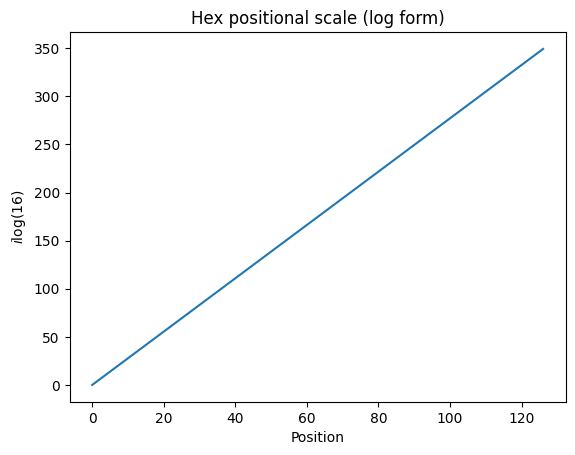

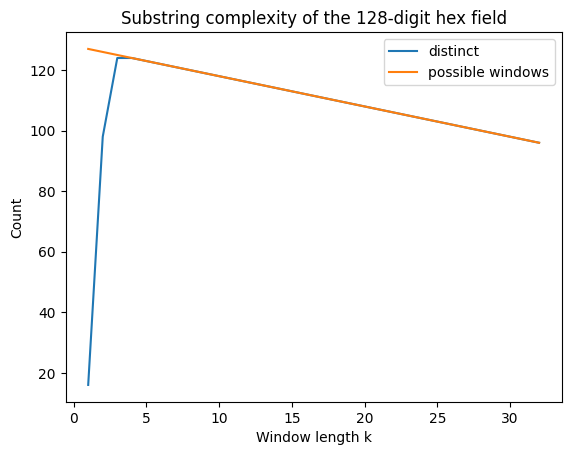

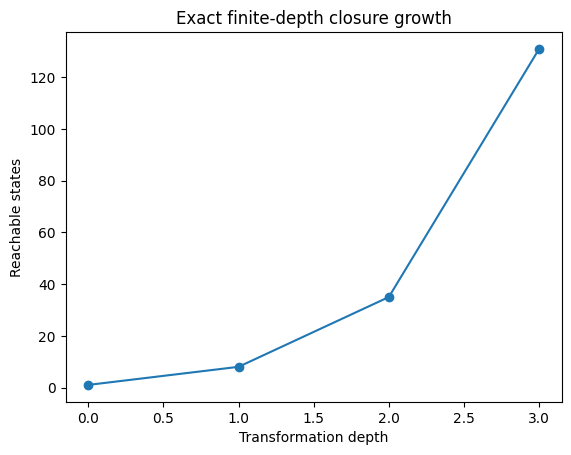

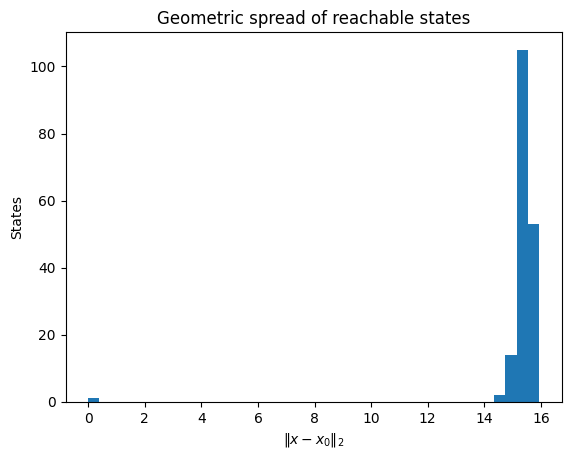

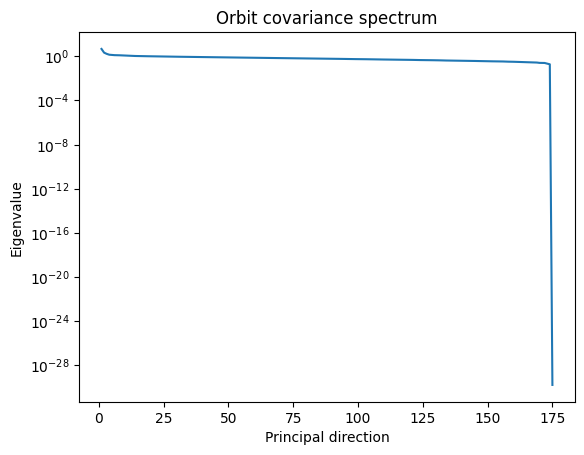

In [19]:

fig, ax = plt.subplots()
ax.plot(scale_df["position"], scale_df["log_scale"])
ax.set_xlabel("Position")
ax.set_ylabel(r"$i\log(16)$")
ax.set_title("Hex positional scale (log form)")
plt.show()

fig, ax = plt.subplots()
ax.plot(complexity_df["k"], complexity_df["distinct"], label="distinct")
ax.plot(complexity_df["k"], complexity_df["max_possible"], label="possible windows")
ax.set_xlabel("Window length k")
ax.set_ylabel("Count")
ax.set_title("Substring complexity of the 128-digit hex field")
ax.legend()
plt.show()

counts = orbit_df.groupby("depth")["id"].count().sort_index()
fig, ax = plt.subplots()
ax.plot(counts.index, counts.values, marker="o")
ax.set_xlabel("Transformation depth")
ax.set_ylabel("Reachable states")
ax.set_title("Exact finite-depth closure growth")
plt.show()

fig, ax = plt.subplots()
ax.hist(distances, bins=40)
ax.set_xlabel(r"$\|x-x_0\|_2$")
ax.set_ylabel("States")
ax.set_title("Geometric spread of reachable states")
plt.show()

if len(orbit_eig):
    fig, ax = plt.subplots()
    ax.semilogy(np.arange(1, len(orbit_eig) + 1), orbit_eig + 1e-30)
    ax.set_xlabel("Principal direction")
    ax.set_ylabel("Eigenvalue")
    ax.set_title("Orbit covariance spectrum")
    plt.show()



## 18. Experiment controls

The notebook intentionally keeps several controls separate.

### Reader control
Change `TRANSFORMS` while keeping the π field fixed.

### Field control
Replace `PI_HEX_128` with another fixed hex source while keeping `TRANSFORMS` fixed.

### Base control
Re-render the same finite payload at another radix.

### Resolution control
Increase `max_depth`, enlarge the operator family, or replace the finite symbolic state with a finer continuous embedding.

### Infinite-source control
Replace the finite input with a streaming hexadecimal source and run the self-addressing trajectory without modulo wrapping.

The central object to compare is not one number. It is the tuple

\[
\boxed{
\mathcal S=
(\text{reachable states},
\text{orbit geometry},
\text{effective dimension},
\text{scale},
\text{history structure})
}
\]

under controlled changes of field and reader.


In [20]:

# ---------------------------------------------------------------------
# MASTER EXPERIMENT CONFIGURATION
# ---------------------------------------------------------------------

CONFIG = {
    "source": "pi_hex_128",
    "base": 16,
    "max_depth": 3,
    "max_states": 100_000,
    "self_address_offset": 1,
    "window_max_k": 32,
}

CONFIG


{'source': 'pi_hex_128',
 'base': 16,
 'max_depth': 3,
 'max_states': 100000,
 'self_address_offset': 1,
 'window_max_k': 32}


# Interpretation boundary

This notebook distinguishes **computed statements** from **interpretive hypotheses**.

Computed:

- exact finite-depth closure for the declared operator family;
- exact state identities;
- substring complexity;
- radix scale;
- local transformation vectors;
- ranks/effective dimensions of those sampled vector families;
- finite self-addressing trajectories.

Not established by these computations:

- that the transformation closure is the physical universe;
- that matter is literally memory;
- that radix is physically fundamental;
- that π is normal;
- that a finite prefix represents the full infinite π field.

Those are hypotheses to be tested by progressively stronger controls.
